In [62]:
import numpy as np
import pandas as pd

import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, roc_auc_score, confusion_matrix
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

import time

# Set seed for reproducibility
np.random.seed(42)
tf.random.set_seed(42)



In [63]:
def load_and_clean_data(csv_path):
    """
    Load and clean the dataset from a CSV file.
    
    Parameters:
        csv_path (str): Path to the CSV file.
    """
    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()
    
    # 1. Extract Target Labels
    if 'label' in df.columns:
        y = df['label'].values.ravel().astype(np.int32) # Ensures 1D array shape: (N,)
    else:
        y = None
    
    # 2. Drop high-cardinality metadata & identifiers
    high_cardinality_drops = [
        'src_ip', 'dst_ip', 'src_port', 'dst_port', 
        'http_user_agent', 'http_uri', 'dns_query', 
        'ssl_subject', 'ssl_issuer', 'weird_name', 'weird_addl',
        'label', 'type'
    ]
    X_df = df.drop(columns=[col for col in high_cardinality_drops if col in df.columns], errors='ignore')

    # 3. Clean string booleans & missing values
    pd.set_option('future.no_silent_downcasting', True) # Opt-in to future Pandas behavior
    
    X_df = X_df.replace({'-': np.nan, 'T': 1, 'F': 0, 'true': 1, 'false': 0, True: 1, False: 0})
    X_df = X_df.infer_objects(copy=False) # Explicitly infer updated data types
    X_df = X_df.fillna(0)

    # 4. One-Hot Encode true categoricals
    cat_cols = X_df.select_dtypes(include=['object', 'category']).columns.tolist()
    if len(cat_cols) > 0:
        X_df = pd.get_dummies(X_df, columns=cat_cols, drop_first=True, dtype=float)

    # 5. Drop Zero-Variance columns
    variance = X_df.var(numeric_only=True)
    zero_var_cols = variance[variance == 0].index.tolist()
    if len(zero_var_cols) > 0:
        X_df = X_df.drop(columns=zero_var_cols)

    # 6. Apply Log1p to skewed features
    skewed_cols = X_df.skew(numeric_only=True)
    high_skew = skewed_cols[skewed_cols > 3.0].index.tolist()
    if len(high_skew) > 0:
        X_df[high_skew] = X_df[high_skew].astype(float)
        X_df[high_skew] = np.log1p(np.maximum(0, X_df[high_skew]))

    X = X_df.values.astype(np.float32)

    print(f"X_test shape befor scaling {X.shape}")
    # 8. Scale Features using MinMaxScaler
    scaler = MinMaxScaler(feature_range=(0, 1))
    X_train_scaled = scaler.fit_transform(X)

    return X, y


In [64]:
def build_autoencoder(input_dim, bottleneck_dim=None):
    # Set bottleneck to ~50% if not specified to avoid over-compression
    if bottleneck_dim is None:
        bottleneck_dim = int(input_dim * 0.50)

    inp = layers.Input(shape=(input_dim,))

    # Encoder Branch
    x = layers.Dense(int(input_dim * 0.75), activation="leaky_relu")(inp)
    
    # Bottleneck Layer (Linear/LeakyReLU keeps negative activation values)
    encoded = layers.Dense(bottleneck_dim, activation="leaky_relu", name="encoded_features")(x)

    # Decoder Branch
    x = layers.Dense(int(input_dim * 0.75), activation="leaky_relu")(encoded)
    
    # Use 'sigmoid' if inputs are scaled [0, 1]; use 'linear' if standard-scaled (Z-score)
    decoded = layers.Dense(input_dim, activation="sigmoid")(x) 

    autoencoder = models.Model(inp, decoded, name="Autoencoder")
    encoder = models.Model(inp, encoded, name="Encoder")

    autoencoder.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="mse"
    )

    return autoencoder, encoder

In [71]:
def get_encoded_features(csv_path, epochs=50, dimensionality_reduction=0.50, batch_size=128):
    X, y = load_and_clean_data(csv_path)
    
    input_dim = X.shape[1]
    bottleneck_dim = int(input_dim * dimensionality_reduction)
    print(f"Building Autoencoder with input features {input_dim}, and Dimensionality reduction {dimensionality_reduction}")
    autoencoder, encoder = build_autoencoder(input_dim, bottleneck_dim=bottleneck_dim)

    # Train the autoencoder
    autoencoder.fit(
        X, X,
        epochs=epochs,
        batch_size=batch_size,
        shuffle=True,
        validation_split=0.2,
        verbose=0
    )

    # Get encoded features
    X_encoded = encoder.predict(X)
    print(f"Autoencoder with output features {X_encoded.shape[1]}")
    return X_encoded, y

In [66]:
def create_sliding_windows(X_data, y_data, sequence_length=10, step=1):
    """
    Converts 2D compressed latent features into 3D temporal sequence arrays.
    Guarantees length synchronization before slicing.
    """
    # 1. Enforce equal sample lengths to prevent out-of-bounds indexing
    min_len = min(len(X_data), len(y_data))
    X_data = X_data[:min_len]
    y_data = y_data[:min_len]
    
    X_seq, y_seq = [], []
    
    # 2. Safely slide window over synchronized arrays
    for i in range(0, min_len - sequence_length + 1, step):
        X_seq.append(X_data[i : i + sequence_length])
        y_seq.append(y_data[i + sequence_length - 1])
        
    return np.array(X_seq, dtype=np.float32), np.array(y_seq, dtype=np.int32)

In [67]:
# ==============================================================================
# 1. Custom Temporal Attention Layer (Your Implementation)
# ==============================================================================
@tf.keras.utils.register_keras_serializable(package="CustomLayers")
class TemporalAttention(layers.Layer):
    def __init__(self, **kwargs):
        layers.Layer.__init__(self, **kwargs)

    def build(self, input_shape):
        self.W = self.add_weight(
            name="att_weight", 
            shape=(input_shape[-1], 1),
            initializer="glorot_uniform", 
            trainable=True
        )
        self.b = self.add_weight(
            name="att_bias", 
            shape=(input_shape[1], 1),
            initializer="zeros", 
            trainable=True
        )
        layers.Layer.build(self, input_shape)

    def call(self, inputs):
        e = tf.math.tanh(tf.tensordot(inputs, self.W, axes=1) + self.b)
        alpha = tf.nn.softmax(e, axis=1)
        context = tf.reduce_sum(inputs * alpha, axis=1)
        return context



In [68]:
# ==============================================================================
# 2. Benchmark Model Builders
# ==============================================================================

# Baseline 1: Static Random Forest (Operates on flattened/static flow features)
def train_rf_baseline(X, y):
    rf = RandomForestClassifier(n_estimators=100, n_jobs=-1)
    X_train_flat, X_test_flat, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y)
    rf.fit(X_train_flat, y_train)
    y_pred = rf.predict(X_test_flat)
    return y_pred, y_test

# Baseline 2: Deep SAE + MLP
def build_sae_mlp(input_shape=(10, 37)):
    inputs = layers.Input(shape=input_shape)
    x = layers.Flatten()(inputs)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.2)(x)
    x = layers.Dense(64, activation="relu")(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = models.Model(inputs, outputs, name="SAE_MLP")
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
    return model

# Baseline 3: Standard CNN-LSTM
def build_cnn_lstm(input_shape=(10, 37)):
    inputs = layers.Input(shape=input_shape)
    x = layers.Conv1D(filters=64, kernel_size=3, padding="same", activation="relu")(inputs)
    x = layers.MaxPooling1D(pool_size=2)(x)
    x = layers.LSTM(64, return_sequences=False)(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = models.Model(inputs, outputs, name="CNN_LSTM")
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
    return model

# Baseline 4: Stacked BiGRU (Without Temporal Attention)
def build_bigru_no_attention(input_shape=(10, 37)):
    inputs = layers.Input(shape=input_shape)
    x = layers.Bidirectional(layers.GRU(128, return_sequences=True, dropout=0.20))(inputs)
    x = layers.Bidirectional(layers.GRU(64, return_sequences=False, dropout=0.20))(x)
    x = layers.Dropout(0.20)(x)
    x = layers.Dense(32, activation="gelu")(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = models.Model(inputs, outputs, name="BiGRU_No_Attention")
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
    return model

# Proposed Model: SD-SAE + BiGRU-Attention
def build_proposed_model(input_shape=(10, 37)):
    inputs = layers.Input(shape=input_shape, name="sequence_input")
    x = layers.Bidirectional(layers.GRU(128, return_sequences=True, dropout=0.20), name="bigru_1")(inputs)
    x = layers.Bidirectional(layers.GRU(64, return_sequences=True, dropout=0.20), name="bigru_2")(x)
    x = TemporalAttention(name="temporal_attention")(x)
    x = layers.Dropout(0.20, name="dropout")(x)
    x = layers.Dense(32, activation="gelu", name="dense_32")(x)
    outputs = layers.Dense(1, activation="sigmoid", name="attack_probability")(x)
    
    model = models.Model(inputs, outputs, name="Proposed_SDSAE_BiGRU_Att")
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
    return model



In [69]:
# ==============================================================================
# 3. Metric Evaluation Helper
# ==============================================================================
def evaluate_metrics(y_true, y_prob):
    # 1. CRITICAL: Convert continuous sigmoid probabilities to binary predictions (0 or 1)
    y_pred = (np.array(y_prob) >= 0.5).astype(int)
    
    # Ensure y_true is strictly integer array
    y_true = np.array(y_true).astype(int)

    # 2. Extract Confusion Matrix parameters
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    # 3. Compute metrics with safe zero_division handling
    acc = accuracy_score(y_true, y_pred) * 100
    
    # Setting zero_division=0 prevents crashes, but explicit binary thresholding fixes the 0% issue
    prec = precision_score(y_true, y_pred, pos_label=1, zero_division=0) * 100
    rec = recall_score(y_true, y_pred, pos_label=1, zero_division=0) * 100
    f1 = f1_score(y_true, y_pred, pos_label=1, zero_division=0) * 100
    auc = roc_auc_score(y_true, y_prob)

    # Calculate False Positive Rate (FPR)
    fpr = (fp / (fp + tn)) * 100 if (fp + tn) > 0 else 0.0

    print(f"Debug Counts -> TP: {tp}, FP: {fp}, TN: {tn}, FN: {fn}")
    
    return {
        "Acc": acc, "Prec": prec, "Rec": rec, 
        "F1": f1, "FPR": fpr, "AUC": auc
    }



In [70]:
print(f"[1/4] Generating Data ...")
X_compressed, y = get_encoded_features(r'ton-iot-train-test-network\train_test_network.csv', epochs=50, batch_size=128)
X_seq, y_seq = create_sliding_windows(X_compressed, y, sequence_length=10, step=1)
X_train, X_test, y_train, y_test = train_test_split(X_seq, y_seq, test_size=0.20, stratify=y_seq)


[1/4] Generating Data ...
X_test shape befor scaling (211043, 75)
Building Autoencoder with input features 75, and Dimensionality reduction 0.5
6596/6596 ━━━━━━━━━━━━━━━━━━━━ 3s 386us/step
Autoencoder with output features 211043


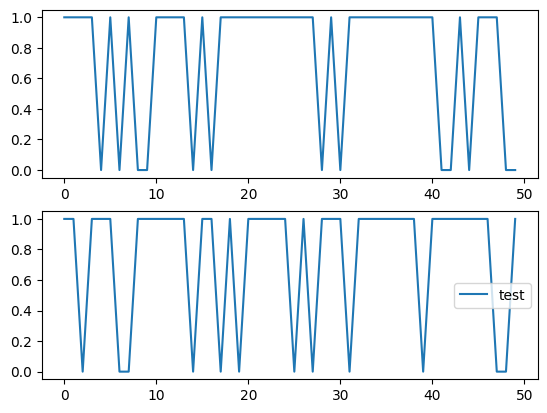

In [72]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(2,1)
axs[0].plot(y_train[:50], label='train')
axs[1].plot(y_test[:50], label='test')
plt.legend()
plt.show()

In [74]:
results = {}

In [75]:
def num_str(num, decimal_places=2):
    """
    Convert a number to a string with commas as thousands separators.
    
    Parameters:
        num (int or float): The number to format.
        decimal_places (int): The number of decimal places to include.
        
    Returns:
        str: The formatted string representation of the number.
    """
    num_str = str(num)
    before_dec, after_dec = num_str.split(".")
    truncated_str = f"{before_dec}.{after_dec[:decimal_places]}"
    return truncated_str

In [77]:
# ==============================================================================
# 4. Main Experiment Execution Suite
# ==============================================================================
def run_centralized_iid_benchmarks():
    print("==========================================================")
    print("  RUNNING CENTRALIZED IID BASELINE EVALUATION SUITE       ")
    print("==========================================================\n")

    window_len = 10
    latent_dim = X_compressed.shape[1]

    # --- 1. Static Random Forest ---
    print("[2/4] Training Baseline 1: Static Random Forest...")
    #X_train_flat = X_train.reshape(X_train.shape[0], -1)
    #X_test_flat = X_test.reshape(X_test.shape[0], -1)

    y_prob_rf, y_test_rf = train_rf_baseline(X_compressed, y)
    results["Static Random Forest (RF)"] = evaluate_metrics(y_test_rf, y_prob_rf)

    # Function to train and test Neural Network Baselines
    def run_nn_model(model_builder, name, epochs=3, batch_size=128):
        print(f"[3/4] Training {name}...")
        model = model_builder((window_len, latent_dim))
        model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, verbose=0)
        
        y_prob = model.predict(X_test, batch_size=batch_size, verbose=0).ravel()
        
        results[name] = evaluate_metrics(y_test, y_prob)

    # --- 2. Deep SAE + MLP ---
    run_nn_model(build_sae_mlp, "Deep SAE + MLP")

    # --- 3. Standard CNN-LSTM ---
    run_nn_model(build_cnn_lstm, "Standard CNN-LSTM")

    # --- 4. Stacked BiGRU (No Attention) ---
    run_nn_model(build_bigru_no_attention, "Stacked BiGRU (without Attention)")

    # --- 5. Proposed Model (SD-SAE + BiGRU-Attention) ---
    print("[4/4] Training Proposed Model (SD-SAE + BiGRU-Attention)...")
    run_nn_model(build_proposed_model, "Proposed (SD-SAE + BiGRU-Att)")

    # ==============================================================================
    # 5. Print Paper-Ready Comparison Table
    # ==============================================================================
    print("\n" + "=" * 80)
    print("  TABLE 1: CENTRALIZED IID BASELINE PERFORMANCE COMPARISON")
    print("=" * 80)
    print(f"{'Model Architecture':<34} | {'Acc (%)':<7} | {'Prec (%)':<8} | {'Rec (%)':<7} | {'F1 (%)':<7} | {'FPR (%)':<7} | {'AUC':<5}")
    print("-" * 80)

    for model_name, metrics in results.items():
        print(
                f"{model_name:<34} | "
                f"{num_str(metrics['Acc']):<7} | "
                f"{num_str(metrics['Prec']):<8} | "
                f"{num_str(metrics['Rec']):<7} | "
                f"{num_str(metrics['F1']):<7} | "
                f"{num_str(metrics['FPR']):<7} | "
                f"{num_str(metrics['AUC'], decimal_places=3):<5}"
            )
    print("-" * 80)



In [78]:
run_centralized_iid_benchmarks()

  RUNNING CENTRALIZED IID BASELINE EVALUATION SUITE       

[2/4] Training Baseline 1: Static Random Forest...
Debug Counts -> TP: 32187, FP: 42, TN: 9958, FN: 22
[3/4] Training Deep SAE + MLP...
Debug Counts -> TP: 32189, FP: 21, TN: 9979, FN: 18
[3/4] Training Standard CNN-LSTM...
Debug Counts -> TP: 32192, FP: 0, TN: 10000, FN: 15
[3/4] Training Stacked BiGRU (without Attention)...
Debug Counts -> TP: 32207, FP: 7, TN: 9993, FN: 0
[4/4] Training Proposed Model (SD-SAE + BiGRU-Attention)...
[3/4] Training Proposed (SD-SAE + BiGRU-Att)...
Debug Counts -> TP: 32204, FP: 7, TN: 9993, FN: 3

  TABLE 1: CENTRALIZED IID BASELINE PERFORMANCE COMPARISON
Model Architecture                 | Acc (%) | Prec (%) | Rec (%) | F1 (%)  | FPR (%) | AUC  
--------------------------------------------------------------------------------
Static Random Forest (RF)          | 99.84   | 99.86    | 99.93   | 99.90   | 0.42    | 0.997
Deep SAE + MLP                     | 99.90   | 99.93    | 99.94   | 99.93  

In [61]:
# ==============================================================================
# 5. Print Paper-Ready Comparison Table
# ==============================================================================
print("\n" + "=" * 80)
print("  TABLE 1: CENTRALIZED IID BASELINE PERFORMANCE COMPARISON")
print("=" * 80)
print(f"{'Model Architecture':<34} | {'Acc (%)':<7} | {'Prec (%)':<8} | {'Rec (%)':<7} | {'F1 (%)':<7} | {'FPR (%)':<7} | {'AUC':<5}")
print("-" * 80)

for model_name, metrics in results.items():
    print(
        f"{model_name:<34} | "
        f"{num_str(metrics['Acc']):<7} | "
        f"{num_str(metrics['Prec']):<8} | "
        f"{num_str(metrics['Rec']):<7} | "
        f"{num_str(metrics['F1']):<7} | "
        f"{num_str(metrics['FPR']):<7} | "
        f"{num_str(metrics['AUC'], decimal_places=3):<5}"
    )
print("-" * 80)


  TABLE 1: CENTRALIZED IID BASELINE PERFORMANCE COMPARISON
Model Architecture                 | Acc (%) | Prec (%) | Rec (%) | F1 (%)  | FPR (%) | AUC  
--------------------------------------------------------------------------------
Static Random Forest (RF)          | 99.78   | 99.81    | 99.90   | 99.85   | 0.59    | 0.996
Deep SAE + MLP                     | 99.90   | 99.93    | 99.94   | 99.93   | 0.21    | 0.999
Standard CNN-LSTM                  | 99.92   | 99.99    | 99.90   | 99.95   | 0.02    | 0.999
Stacked BiGRU (without Attention)  | 99.96   | 99.96    | 99.99   | 99.97   | 0.11    | 0.999
Proposed (SD-SAE + BiGRU-Att)      | 99.96   | 99.95    | 99.99   | 99.97   | 0.13    | 0.999
--------------------------------------------------------------------------------
